# Citi Bike - Assignment

In [45]:
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_FILE = ROOT / "data" / "raw" / "raw_data.csv"
CHART_DIR = ROOT / "output-charts"
CHART_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.width", 200)

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
USER_COLORS = {"Subscriber": "#0072B2", "Customer": "#E69F00"}
GENDER_COLORS = {"Male": "#009E73", "Female": "#CC79A7", "Unknown": "#A0A0A0"}
DAY_TYPE_COLORS = {"Weekday": "#56B4E9", "Weekend": "#D55E00"}


def print_task2(data_types, marks_channels, best_practices, justification):
    """Print the Task 2 answers (a-d) for one visualization."""
    print("Task 2 - about this visualization")
    for label, text in [("a. Data types", data_types), ("b. Marks & channels", marks_channels),
                        ("c. Best practices", best_practices), ("d. Justification", justification)]:
        print(f"\n{label}:")
        print(textwrap.fill(text, width=100, initial_indent="   ", subsequent_indent="   "))


def show_chart(number):
    """Save the current figure as output-charts/<number>.png, then show it."""
    plt.savefig(CHART_DIR / f"{number}.png", bbox_inches="tight")
    plt.show()

## 1. Load the data

In [46]:
df = pd.read_csv(DATA_FILE)

# The first column is a leftover pandas index; 'Trip_Duration_in_min' is just round(Trip Duration / 60).
df = df.drop(columns=[df.columns[0], "Trip_Duration_in_min"])
df = df.rename(columns={
    "Trip Duration": "trip_duration", "Start Time": "start_time", "Stop Time": "stop_time",
    "Start Station ID": "start_station_id", "Start Station Name": "start_station_name",
    "Start Station Latitude": "start_lat", "Start Station Longitude": "start_lon",
    "End Station ID": "end_station_id", "End Station Name": "end_station_name",
    "End Station Latitude": "end_lat", "End Station Longitude": "end_lon",
    "Bike ID": "bike_id", "User Type": "user_type", "Birth Year": "birth_year", "Gender": "gender",
})
print(df.shape)
df.head()

(735502, 15)


,trip_duration,start_time,stop_time,start_station_id,start_station_name,start_lat,start_lon,end_station_id,end_station_name,end_lat,end_lon,bike_id,user_type,birth_year,gender
0,376,10/1/2015 0:16,10/1/2015 0:22,3212,Christ Hospital,40.734786,-74.050444,3207,Oakland Ave,40.737604,-74.052478,24470,Subscriber,1960,1
1,739,10/1/2015 0:27,10/1/2015 0:39,3207,Oakland Ave,40.737604,-74.052478,3212,Christ Hospital,40.734786,-74.050444,24481,Subscriber,1960,1
2,2714,10/1/2015 0:32,10/1/2015 1:18,3193,Lincoln Park,40.724605,-74.078406,3193,Lincoln Park,40.724605,-74.078406,24628,Subscriber,1983,1
3,275,10/1/2015 0:34,10/1/2015 0:39,3199,Newport Pkwy,40.728745,-74.032108,3187,Warren St,40.721124,-74.038051,24613,Subscriber,1975,1
4,561,10/1/2015 0:40,10/1/2015 0:49,3183,Exchange Place,40.716247,-74.033459,3192,Liberty Light Rail,40.711242,-74.055701,24668,Customer,1984,0


In [47]:
df.isna().sum()

trip_duration         0
start_time            0
stop_time             0
start_station_id      0
start_station_name    0
start_lat             0
start_lon             0
end_station_id        0
end_station_name      0
end_lat               0
end_lon               0
bike_id               0
user_type             0
birth_year            0
gender                0
dtype: int64

## 2. Mandatory cleaning

Only the steps that change the answers:

1. **Exact duplicates** - every monthly file was appended at least twice, so without this every count is doubled.
2. **Datetimes** - parse `start_time` / `stop_time`.
3. **Impossible trips** - stop before start or duration <= 0.
4. **Trips longer than 24 h** - unreturned bikes / system errors, not rides.
5. **Placeholder birth year** - almost every Customer has birth year 1984 (a fill-in value), so it is set to
   missing. Age charts also use only ages 16-80. These rows are kept for all non-age questions, and
   question c shows them as an "Unknown" age group.

In [48]:
rows_start = len(df)

# 1. duplicates
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {rows_start - len(df):,}")

# 2. datetimes
df["start_time"] = pd.to_datetime(df["start_time"], format="%m/%d/%Y %H:%M")
df["stop_time"] = pd.to_datetime(df["stop_time"], format="%m/%d/%Y %H:%M")

# 3. impossible trips
bad_time = (df["stop_time"] < df["start_time"]) | (df["trip_duration"] <= 0)
df = df[~bad_time]
print(f"Impossible trips removed: {bad_time.sum():,}")

# 4. trips over 24 hours
too_long = df["trip_duration"] > 24 * 3600
df = df[~too_long].reset_index(drop=True)
print(f"Trips > 24 h removed: {too_long.sum():,}")

# 5. placeholder birth year for Customers
print("Most common Customer birth years:")
print(df.loc[df["user_type"] == "Customer", "birth_year"].value_counts(normalize=True).head(3))
placeholder = (df["user_type"] == "Customer") & (df["birth_year"] == 1984)
df["birth_year"] = df["birth_year"].mask(placeholder)
print(f"Placeholder birth years set to missing: {placeholder.sum():,}")

print(f"\nRows: {rows_start:,} -> {len(df):,}")

Duplicates removed: 395,882
Impossible trips removed: 4
Trips > 24 h removed: 146
Most common Customer birth years:
birth_year
1984    0.997614
1983    0.000367
1992    0.000321
Name: proportion, dtype: float64
Placeholder birth years set to missing: 21,746

Rows: 735,502 -> 339,470


## 3. Derived columns

In [49]:
df["duration_min"] = df["trip_duration"] / 60
df["date"] = df["start_time"].dt.normalize()
df["year"] = df["start_time"].dt.year
df["month"] = df["start_time"].dt.month
df["month_name"] = pd.Categorical(df["start_time"].dt.strftime("%b"), categories=MONTHS, ordered=True)
df["year_month"] = df["start_time"].dt.to_period("M")
df["hour"] = df["start_time"].dt.hour
df["day_of_week"] = pd.Categorical(df["start_time"].dt.day_name(), categories=DAYS, ordered=True)
df["is_weekend"] = df["day_of_week"].isin(["Saturday", "Sunday"])
df["gender_label"] = df["gender"].map({0: "Unknown", 1: "Male", 2: "Female"})

df["age"] = df["year"] - df["birth_year"]
df["valid_age"] = df["age"].between(16, 80)
df["age_group"] = pd.cut(df["age"].where(df["valid_age"]), bins=[16, 25, 35, 45, 55, 65, 81],
                         labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"], right=False)

print(f"Data period: {df['start_time'].min():%d %b %Y} - {df['start_time'].max():%d %b %Y}")
df.head()

Data period: 21 Sep 2015 - 31 Mar 2017


,trip_duration,start_time,stop_time,start_station_id,start_station_name,start_lat,start_lon,end_station_id,end_station_name,end_lat,...,month,month_name,year_month,hour,day_of_week,is_weekend,gender_label,age,valid_age,age_group
0,376,2015-10-01 00:16:00,2015-10-01 00:22:00,3212,Christ Hospital,40.734786,-74.050444,3207,Oakland Ave,40.737604,...,10,Oct,2015-10,0,Thursday,False,Male,55.0,True,55-64
1,739,2015-10-01 00:27:00,2015-10-01 00:39:00,3207,Oakland Ave,40.737604,-74.052478,3212,Christ Hospital,40.734786,...,10,Oct,2015-10,0,Thursday,False,Male,55.0,True,55-64
2,2714,2015-10-01 00:32:00,2015-10-01 01:18:00,3193,Lincoln Park,40.724605,-74.078406,3193,Lincoln Park,40.724605,...,10,Oct,2015-10,0,Thursday,False,Male,32.0,True,25-34
3,275,2015-10-01 00:34:00,2015-10-01 00:39:00,3199,Newport Pkwy,40.728745,-74.032108,3187,Warren St,40.721124,...,10,Oct,2015-10,0,Thursday,False,Male,40.0,True,35-44
4,561,2015-10-01 00:40:00,2015-10-01 00:49:00,3183,Exchange Place,40.716247,-74.033459,3192,Liberty Light Rail,40.711242,...,10,Oct,2015-10,0,Thursday,False,Unknown,NaN,False,NaN


## a. How does the average trip duration change throughout the day across months?
Median is used instead of mean because trip durations have a long right tail.

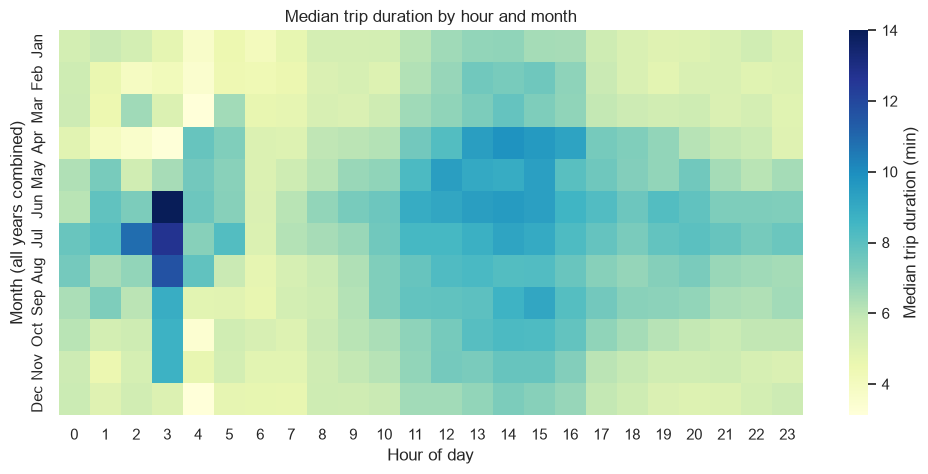

Task 2 - about this visualization

a. Data types:
   Ordinal: month, hour of day. Quantitative: median trip duration (minutes).

b. Marks & channels:
   Mark: area (one heatmap cell per month x hour). Channels: horizontal position = hour, vertical
   position = month, colour luminance on a sequential scale = median duration.

c. Best practices:
   Median instead of mean because trip durations are right-skewed; sequential, colour-blind-safe
   colormap (YlGnBu); colour bar labelled with units; months and hours in natural order; all years
   combined so every month has enough trips.

d. Justification:
   Two ordered dimensions against one quantity (12 x 24 = 288 values) fit compactly in a heatmap.
   Reading along a row shows the daily cycle and reading down a column shows the seasonal change,
   which is exactly what the question asks.


In [50]:
qa = df.pivot_table(index="month_name", columns="hour", values="duration_min",
                    aggfunc="median", observed=False)

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(qa, cmap="YlGnBu", cbar_kws={"label": "Median trip duration (min)"}, ax=ax)
ax.set_title("Median trip duration by hour and month")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Month (all years combined)")
show_chart(1)

print_task2(
    data_types='Ordinal: month, hour of day. Quantitative: median trip duration (minutes).',
    marks_channels=(
        'Mark: area (one heatmap cell per month x hour). Channels: horizontal position = hour, '
        'vertical position = month, colour luminance on a sequential scale = median duration.'
    ),
    best_practices=(
        'Median instead of mean because trip durations are right-skewed; sequential, colour-'
        'blind-safe colormap (YlGnBu); colour bar labelled with units; months and hours in '
        'natural order; all years combined so every month has enough trips.'
    ),
    justification=(
        'Two ordered dimensions against one quantity (12 x 24 = 288 values) fit compactly in a '
        'heatmap. Reading along a row shows the daily cycle and reading down a column shows the '
        'seasonal change, which is exactly what the question asks.'
    ),
)

## b. Which stations have the highest traffic, and how does this vary by gender?

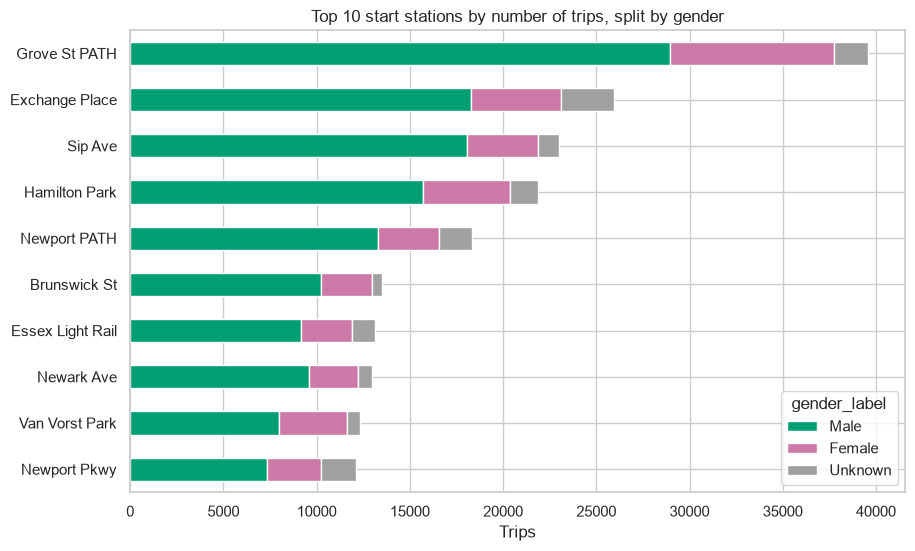

gender_label,Male,Female,Unknown
start_station_name,,,
Grove St PATH,28974,8764,1851
Exchange Place,18289,4803,2841
Sip Ave,18091,3804,1082
Hamilton Park,15689,4697,1487
Newport PATH,13272,3275,1795
Brunswick St,10216,2747,521
Essex Light Rail,9166,2706,1253
Newark Ave,9610,2619,756
Van Vorst Park,8003,3621,681


Task 2 - about this visualization

a. Data types:
   Nominal: start station, gender. Quantitative: trip count.

b. Marks & channels:
   Mark: bar. Channels: vertical position = station, bar length = trip count, colour hue = gender
   (stacked segments).

c. Best practices:
   Bars sorted with the busiest station on top; common zero baseline; horizontal bars so station
   names stay readable; Unknown gender in neutral grey; the same gender colours are reused in d, f
   and k; summary table printed for exact values.

d. Justification:
   A stacked horizontal bar answers both parts at once: total bar length ranks the stations by
   traffic, and the segments show how that traffic splits by gender. Traffic = trips started at the
   station.


In [51]:
top10 = df["start_station_name"].value_counts().head(10).index
qb = pd.crosstab(df.loc[df["start_station_name"].isin(top10), "start_station_name"],
                 df["gender_label"])[["Male", "Female", "Unknown"]]
qb = qb.loc[top10]

ax = qb.iloc[::-1].plot.barh(stacked=True, color=GENDER_COLORS, figsize=(10, 6))
ax.set_title("Top 10 start stations by number of trips, split by gender")
ax.set_xlabel("Trips")
ax.set_ylabel("")
show_chart(2)
display(qb)

print_task2(
    data_types='Nominal: start station, gender. Quantitative: trip count.',
    marks_channels=(
        'Mark: bar. Channels: vertical position = station, bar length = trip count, colour hue = '
        'gender (stacked segments).'
    ),
    best_practices=(
        'Bars sorted with the busiest station on top; common zero baseline; horizontal bars so '
        'station names stay readable; Unknown gender in neutral grey; the same gender colours are'
        ' reused in d, f and k; summary table printed for exact values.'
    ),
    justification=(
        'A stacked horizontal bar answers both parts at once: total bar length ranks the stations'
        ' by traffic, and the segments show how that traffic splits by gender. Traffic = trips '
        'started at the station.'
    ),
)

## c. What is the distribution of user types across different age groups?

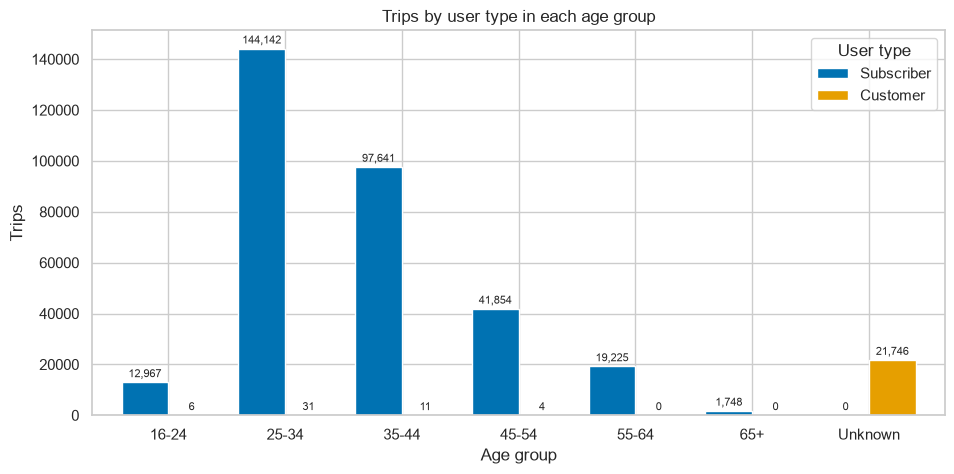

Note: 'Unknown' = 21,746 trips with no birth year (21,746 of them Customers with the masked 1984 placeholder). 95 trips with ages outside 16-80 are left out.


user_type,Subscriber,Customer
age_group,,
16-24,12967,6
25-34,144142,31
35-44,97641,11
45-54,41854,4
55-64,19225,0
65+,1748,0
Unknown,0,21746


Task 2 - about this visualization

a. Data types:
   Ordinal: age group (plus an Unknown group). Nominal: user type. Quantitative: trip count.

b. Marks & channels:
   Mark: bar. Channels: horizontal position = age group, side-by-side position within the group +
   colour hue = user type, bar height = trip count.

c. Best practices:
   Grouped bars on a common zero baseline so Subscriber and Customer counts are compared directly;
   bars labelled with exact counts; age groups in order with Unknown last; same user-type colours as
   e and j; missing ages shown as their own group instead of hidden.

d. Justification:
   Counts show how many trips each user type makes in each age group, not just the split. Showing
   the Unknown group is needed for honesty: almost every Customer has no real birth year, so without
   it Customers would seem to barely use the system.


In [52]:
# Trips with no birth year (mostly the Customers whose placeholder 1984 was masked) get their own "Unknown" group.
age_group_c = df["age_group"].cat.add_categories("Unknown")
age_group_c[df["birth_year"].isna()] = "Unknown"
qc = pd.crosstab(age_group_c, df["user_type"])[["Subscriber", "Customer"]]

ax = qc.plot.bar(color=USER_COLORS, rot=0, figsize=(11, 5), width=0.8)
for bars in ax.containers:
    ax.bar_label(bars, fmt="{:,.0f}", fontsize=8, padding=2)
ax.set_title("Trips by user type in each age group")
ax.set_xlabel("Age group")
ax.set_ylabel("Trips")
ax.legend(title="User type", bbox_to_anchor=(1, 1))
show_chart(3)

out_of_range = df["birth_year"].notna() & ~df["valid_age"]
print(f"Note: 'Unknown' = {qc.loc['Unknown'].sum():,} trips with no birth year "
      f"({qc.loc['Unknown', 'Customer']:,} of them Customers with the masked 1984 placeholder). "
      f"{out_of_range.sum():,} trips with ages outside 16-80 are left out.")
display(qc)

print_task2(
    data_types='Ordinal: age group (plus an Unknown group). Nominal: user type. Quantitative: trip count.',
    marks_channels=(
        'Mark: bar. Channels: horizontal position = age group, side-by-side position within the '
        'group + colour hue = user type, bar height = trip count.'
    ),
    best_practices=(
        'Grouped bars on a common zero baseline so Subscriber and Customer counts are compared '
        'directly; bars labelled with exact counts; age groups in order with Unknown last; same '
        'user-type colours as e and j; missing ages shown as their own group instead of hidden.'
    ),
    justification=(
        'Counts show how many trips each user type makes in each age group, not just the split. '
        'Showing the Unknown group is needed for honesty: almost every Customer has no real birth '
        'year, so without it Customers would seem to barely use the system.'
    ),
)

## d. What is the age and gender distribution of Citi Bike users?

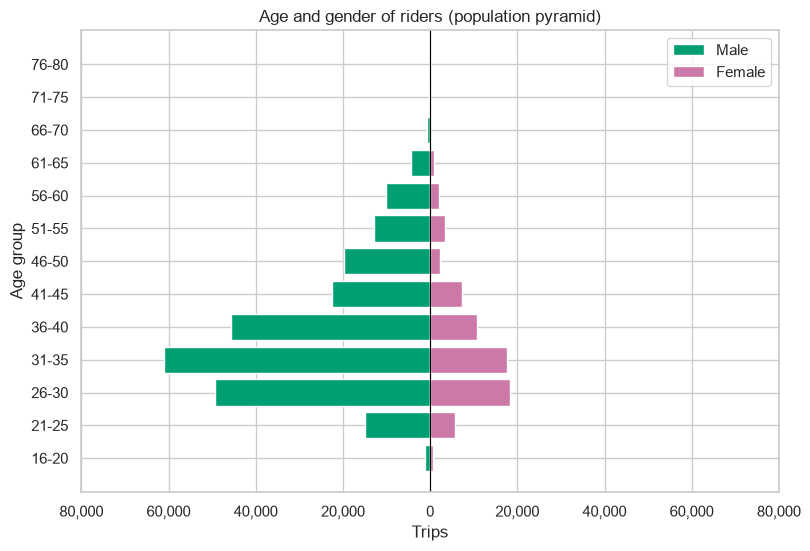

Task 2 - about this visualization

a. Data types:
   Ordinal: 5-year age bin. Nominal: gender. Quantitative: trip count.

b. Marks & channels:
   Mark: bar. Channels: vertical position = age bin, bar length = trip count, direction (left/right)
   and colour hue = gender.

c. Best practices:
   Symmetric x axis with absolute (positive) tick labels so both sides use the same scale; zero line
   in the middle; only valid ages (16-80) and known gender; same gender colours as b, f and k.

d. Justification:
   A population pyramid is the standard chart for an age x gender distribution: it shows the shape
   of each gender's age distribution and the gap between genders at every age in one view.


In [53]:
qd_data = df[df["valid_age"] & df["gender_label"].isin(["Male", "Female"])]
qd = pd.crosstab(pd.cut(qd_data["age"], bins=range(16, 86, 5), right=False), qd_data["gender_label"])

fig, ax = plt.subplots(figsize=(9, 6))
labels = [f"{b.left:.0f}-{b.right - 1:.0f}" for b in qd.index]
ax.barh(labels, -qd["Male"], color=GENDER_COLORS["Male"], label="Male")
ax.barh(labels, qd["Female"], color=GENDER_COLORS["Female"], label="Female")
lim = qd.values.max() * 1.05
ax.set_xlim(-lim, lim)   # same scale on both sides
ax.set_xticks(ax.get_xticks(),[f"{abs(x):,.0f}" for x in ax.get_xticks()])
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Age and gender of riders (population pyramid)")
ax.set_xlabel("Trips")
ax.set_ylabel("Age group")
ax.legend()
show_chart(4)

print_task2(
    data_types='Ordinal: 5-year age bin. Nominal: gender. Quantitative: trip count.',
    marks_channels=(
        'Mark: bar. Channels: vertical position = age bin, bar length = trip count, direction '
        '(left/right) and colour hue = gender.'
    ),
    best_practices=(
        'Symmetric x axis with absolute (positive) tick labels so both sides use the same scale; '
        'zero line in the middle; only valid ages (16-80) and known gender; same gender colours '
        'as b, f and k.'
    ),
    justification=(
        'A population pyramid is the standard chart for an age x gender distribution: it shows '
        "the shape of each gender's age distribution and the gap between genders at every age in "
        'one view.'
    ),
)

## e. What percentage of trips are made by each user type over the three years?
Note: the data covers 21 Sep 2015 - 31 Mar 2017, so 2015 and 2017 are partial years.

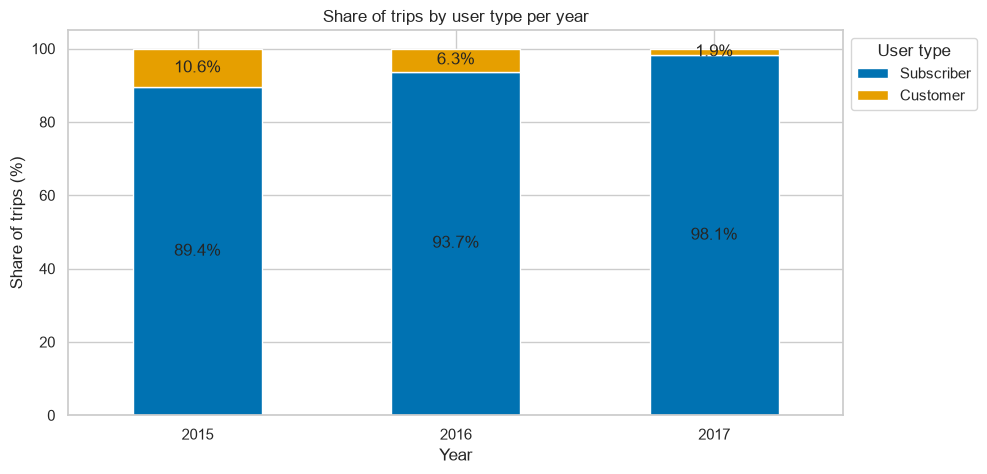

user_type,Customer,Subscriber
year,,
2015,10.6,89.4
2016,6.3,93.7
2017,1.9,98.1


Task 2 - about this visualization

a. Data types:
   Ordinal/temporal: year. Nominal: user type. Quantitative: share of trips (%).

b. Marks & channels:
   Mark: bar. Channels: horizontal position = year, stacked bar height = % share, colour hue = user
   type; text labels = exact %.

c. Best practices:
   100% stacked bars with % labels; same user-type colours as c and j; the partial years (2015 =
   Sep-Dec, 2017 = Jan-Mar) are stated so they are not over-interpreted.

d. Justification:
   With only 2 categories and 3 time points, a 100% stacked bar is the clearest way to compare
   proportions between years.


In [54]:
qe = pd.crosstab(df["year"], df["user_type"], normalize="index") * 100

ax = qe[["Subscriber", "Customer"]].plot.bar(stacked=True, color=USER_COLORS, rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center")
ax.set_title("Share of trips by user type per year")
ax.set_xlabel("Year")
ax.set_ylabel("Share of trips (%)")
ax.legend(title="User type", bbox_to_anchor=(1, 1))
show_chart(5)
display(qe.round(1))

print_task2(
    data_types='Ordinal/temporal: year. Nominal: user type. Quantitative: share of trips (%).',
    marks_channels=(
        'Mark: bar. Channels: horizontal position = year, stacked bar height = % share, colour '
        'hue = user type; text labels = exact %.'
    ),
    best_practices=(
        '100% stacked bars with % labels; same user-type colours as c and j; the partial years '
        '(2015 = Sep-Dec, 2017 = Jan-Mar) are stated so they are not over-interpreted.'
    ),
    justification=(
        'With only 2 categories and 3 time points, a 100% stacked bar is the clearest way to '
        'compare proportions between years.'
    ),
)

## f. What proportion of rides were taken by each gender in each year?

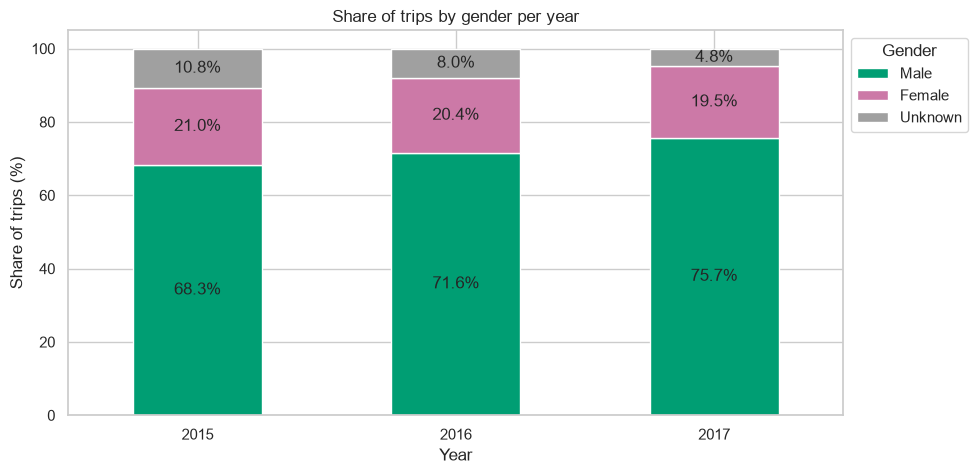

gender_label,Male,Female,Unknown
year,,,
2015,68.3,21.0,10.8
2016,71.6,20.4,8.0
2017,75.7,19.5,4.8


Task 2 - about this visualization

a. Data types:
   Ordinal/temporal: year. Nominal: gender. Quantitative: share of trips (%).

b. Marks & channels:
   Mark: bar. Channels: horizontal position = year, stacked bar height = % share, colour hue =
   gender; text labels = exact %.

c. Best practices:
   Same layout as e for consistency; same gender colours as b, d and k; Unknown in neutral grey; %
   labels on every segment.

d. Justification:
   Same reasoning as e: a part-to-whole comparison for a small number of categories and years.


In [55]:
qf = pd.crosstab(df["year"], df["gender_label"], normalize="index")[["Male", "Female", "Unknown"]] * 100

ax = qf.plot.bar(stacked=True, color=GENDER_COLORS, rot=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center")
ax.set_title("Share of trips by gender per year")
ax.set_xlabel("Year")
ax.set_ylabel("Share of trips (%)")
ax.legend(title="Gender", bbox_to_anchor=(1, 1))
show_chart(6)
display(qf.round(1))

print_task2(
    data_types='Ordinal/temporal: year. Nominal: gender. Quantitative: share of trips (%).',
    marks_channels=(
        'Mark: bar. Channels: horizontal position = year, stacked bar height = % share, colour '
        'hue = gender; text labels = exact %.'
    ),
    best_practices=(
        'Same layout as e for consistency; same gender colours as b, d and k; Unknown in neutral '
        'grey; % labels on every segment.'
    ),
    justification=(
        'Same reasoning as e: a part-to-whole comparison for a small number of categories and '
        'years.'
    ),
)

## g. How has the number of daily rides changed over the three years?

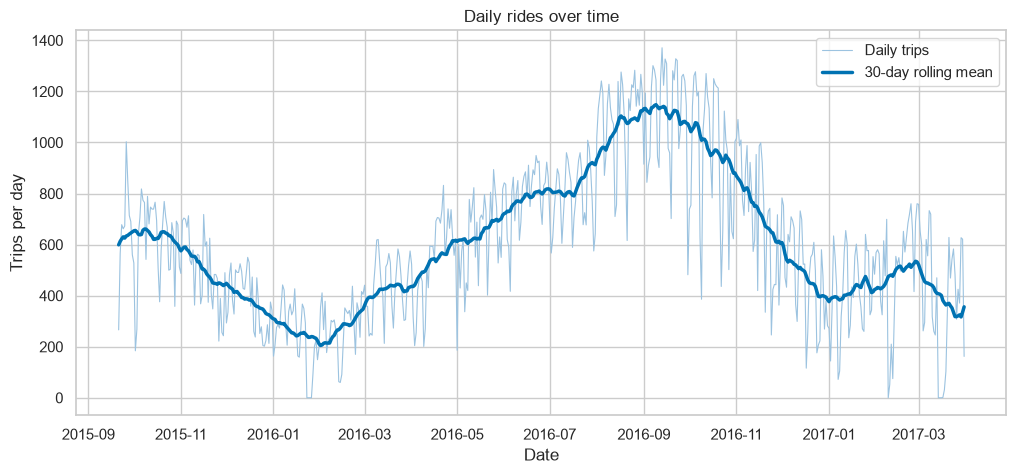

Busiest day: 13 Sep 2016 (1,371 trips)
Task 2 - about this visualization

a. Data types:
   Temporal: date. Quantitative: trips per day and 30-day rolling mean.

b. Marks & channels:
   Mark: line. Channels: horizontal position = date, vertical position = trip count; line thickness
   and lightness separate the raw daily values from the smoothed trend.

c. Best practices:
   Days without trips filled with 0 instead of skipped; 30-day rolling mean shows the trend under
   the daily noise; zero baseline; the busiest day is printed.

d. Justification:
   A line chart is the standard choice for a long, continuous time series. Overlaying the rolling
   mean shows the seasonal pattern while keeping the day-to-day variation visible.


In [56]:
qg = df.groupby("date").size()
qg = qg.reindex(pd.date_range(qg.index.min(), qg.index.max()), fill_value=0)   # days with no trips = 0

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(qg.index, qg, color="#9CC3E0", lw=0.8, label="Daily trips")
ax.plot(qg.index, qg.rolling(30, center=True, min_periods=15).mean(), color="#0072B2", lw=2.5,
        label="30-day rolling mean")
ax.set_title("Daily rides over time")
ax.set_xlabel("Date")
ax.set_ylabel("Trips per day")
ax.legend()
show_chart(7)
print(f"Busiest day: {qg.idxmax():%d %b %Y} ({qg.max():,} trips)")

print_task2(
    data_types='Temporal: date. Quantitative: trips per day and 30-day rolling mean.',
    marks_channels=(
        'Mark: line. Channels: horizontal position = date, vertical position = trip count; line '
        'thickness and lightness separate the raw daily values from the smoothed trend.'
    ),
    best_practices=(
        'Days without trips filled with 0 instead of skipped; 30-day rolling mean shows the trend'
        ' under the daily noise; zero baseline; the busiest day is printed.'
    ),
    justification=(
        'A line chart is the standard choice for a long, continuous time series. Overlaying the '
        'rolling mean shows the seasonal pattern while keeping the day-to-day variation visible.'
    ),
)

## h. Is there a relationship between daily trip count and average trip duration?

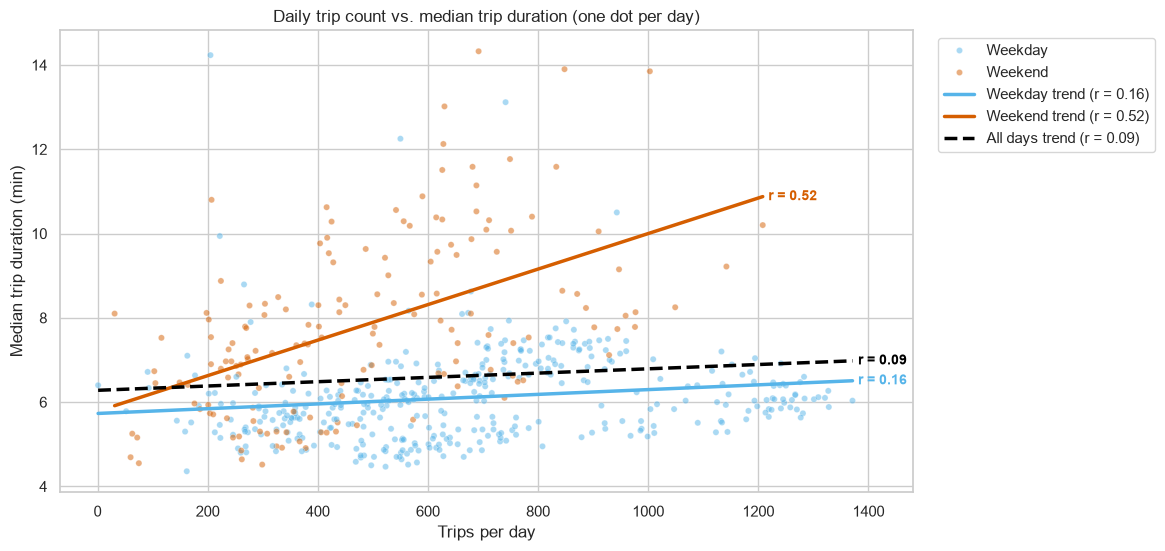

,days,Pearson r,Spearman r
Weekday,394,0.16,0.31
Weekend,156,0.52,0.53
All days,550,0.09,0.19


Task 2 - about this visualization

a. Data types:
   Quantitative: trips per day, median trip duration per day. Nominal: day type (weekday / weekend).

b. Marks & channels:
   Marks: point (one per day) and line (linear trend). Channels: horizontal position = daily trips,
   vertical position = median duration, colour hue = weekday vs weekend; line colour and style =
   which group the trend belongs to (dashed black = all days); text = Pearson r of each trend.

c. Best practices:
   Median duration per day (robust to a few very long trips); semi-transparent points against
   overplotting; colour-blind-safe colours; each trend line labelled with its correlation directly
   on the chart; Pearson and Spearman r shown in a table.

d. Justification:
   A scatter plot is the standard chart for the relationship between two quantitative variables.
   Splitting weekdays and weekends shows that the weak overall correlation hides two different
   patterns: on weekends busier days have clearly lon

In [57]:
qh = df.groupby("date").agg(daily_trips=("duration_min", "size"),
                            median_duration=("duration_min", "median"),
                            is_weekend=("is_weekend", "first"))
qh["day_type"] = qh["is_weekend"].map({False: "Weekday", True: "Weekend"})

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=qh, x="daily_trips", y="median_duration", hue="day_type",
                palette=DAY_TYPE_COLORS, s=20, alpha=0.5, ax=ax)

# Linear trend for weekdays, weekends and all days, labelled with its Pearson r.
trends = [("Weekday", qh[qh["day_type"] == "Weekday"], DAY_TYPE_COLORS["Weekday"], "-"),
          ("Weekend", qh[qh["day_type"] == "Weekend"], DAY_TYPE_COLORS["Weekend"], "-"),
          ("All days", qh, "black", "--")]
corr = {}
for name, d, color, ls in trends:
    corr[name] = d["daily_trips"].corr(d["median_duration"])
    slope, intercept = np.polyfit(d["daily_trips"], d["median_duration"], 1)
    x = np.array([d["daily_trips"].min(), d["daily_trips"].max()])
    ax.plot(x, slope * x + intercept, color=color, ls=ls, lw=2.5,
            label=f"{name} trend (r = {corr[name]:.2f})")
    ax.annotate(f"r = {corr[name]:.2f}", (x[1], slope * x[1] + intercept), xytext=(4, 0),
                textcoords="offset points", color=color, fontsize=10, fontweight="bold", va="center")

ax.set_title("Daily trip count vs. median trip duration (one dot per day)")
ax.set_xlabel("Trips per day")
ax.set_ylabel("Median trip duration (min)")
ax.set_xlim(right=qh["daily_trips"].max() * 1.08)
ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
show_chart(8)

display(pd.DataFrame({
    "days": [len(qh[qh["day_type"] == "Weekday"]), len(qh[qh["day_type"] == "Weekend"]), len(qh)],
    "Pearson r": corr.values(),
    "Spearman r": [d["daily_trips"].corr(d["median_duration"], method="spearman") for _, d, _, _ in trends],
}, index=corr.keys()).round(2))

print_task2(
    data_types='Quantitative: trips per day, median trip duration per day. Nominal: day type (weekday / weekend).',
    marks_channels=(
        'Marks: point (one per day) and line (linear trend). Channels: horizontal position = '
        'daily trips, vertical position = median duration, colour hue = weekday vs weekend; line '
        'colour and style = which group the trend belongs to (dashed black = all days); text = '
        'Pearson r of each trend.'
    ),
    best_practices=(
        'Median duration per day (robust to a few very long trips); semi-transparent points '
        'against overplotting; colour-blind-safe colours; each trend line labelled with its '
        'correlation directly on the chart; Pearson and Spearman r shown in a table.'
    ),
    justification=(
        'A scatter plot is the standard chart for the relationship between two quantitative '
        'variables. Splitting weekdays and weekends shows that the weak overall correlation hides '
        'two different patterns: on weekends busier days have clearly longer trips (leisure '
        'riding), while on weekdays duration barely changes with volume (commuting).'
    ),
)

## i. How do trip duration, user type, gender and age relate to start station selection?
Profile of the 10 busiest start stations. Colours compare the stations with each other (z-score);
the numbers are the real values.

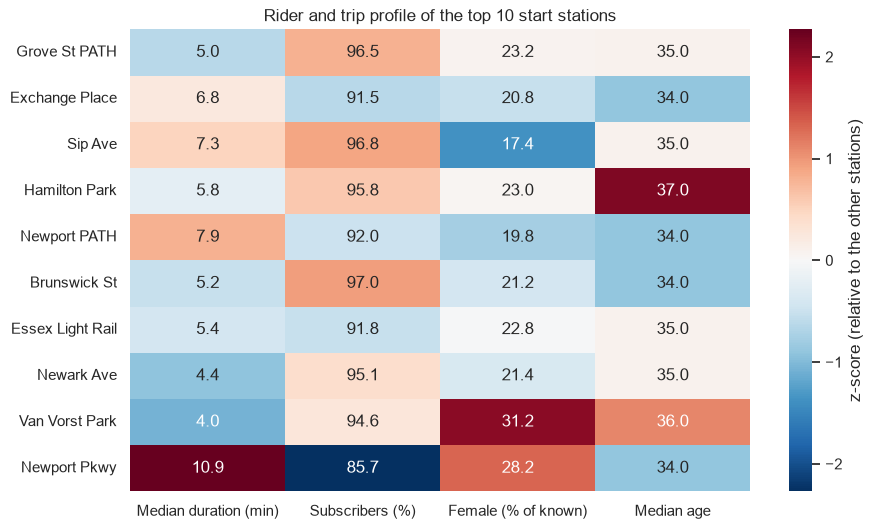

Task 2 - about this visualization

a. Data types:
   Nominal: start station, factor. Quantitative: median duration, % subscribers, % female, median
   age.

b. Marks & channels:
   Mark: area (heatmap cell). Channels: horizontal position = factor, vertical position = station,
   colour hue + luminance on a diverging scale = z-score; text = actual value.

c. Best practices:
   Each factor converted to a z-score so factors with different units share one colour scale;
   diverging colormap centred at 0 (average); cells annotated with the real values; stations ordered
   by traffic.

d. Justification:
   A heatmap 'profile table' compares many stations on several factors at once and shows which
   station is unusual on which factor - the colour shows the comparison, the numbers keep it
   precise.


In [58]:
top10_df = df[df["start_station_name"].isin(top10)]
g = top10_df.groupby("start_station_name")
qi = pd.DataFrame({
    "Median duration (min)": g["duration_min"].median(),
    "Subscribers (%)": g["user_type"].apply(lambda s: (s == "Subscriber").mean() * 100),
    "Female (% of known)": top10_df[top10_df["gender_label"] != "Unknown"]
                               .groupby("start_station_name")["gender_label"]
                               .apply(lambda s: (s == "Female").mean() * 100),
    "Median age": top10_df[top10_df["valid_age"]].groupby("start_station_name")["age"].median(),
}).loc[top10]

z_scores = (qi - qi.mean()) / qi.std()
fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(z_scores, annot=qi.round(1), fmt="", cmap="RdBu_r", center=0,
            cbar_kws={"label": "z-score (relative to the other stations)"}, ax=ax)
ax.set_title("Rider and trip profile of the top 10 start stations")
ax.set_ylabel("")
show_chart(9)

print_task2(
    data_types=(
        'Nominal: start station, factor. Quantitative: median duration, % subscribers, % female, '
        'median age.'
    ),
    marks_channels=(
        'Mark: area (heatmap cell). Channels: horizontal position = factor, vertical position = '
        'station, colour hue + luminance on a diverging scale = z-score; text = actual value.'
    ),
    best_practices=(
        'Each factor converted to a z-score so factors with different units share one colour '
        'scale; diverging colormap centred at 0 (average); cells annotated with the real values; '
        'stations ordered by traffic.'
    ),
    justification=(
        "A heatmap 'profile table' compares many stations on several factors at once and shows "
        'which station is unusual on which factor - the colour shows the comparison, the numbers '
        'keep it precise.'
    ),
)

## j. How do trips by user type vary over the months in each year?

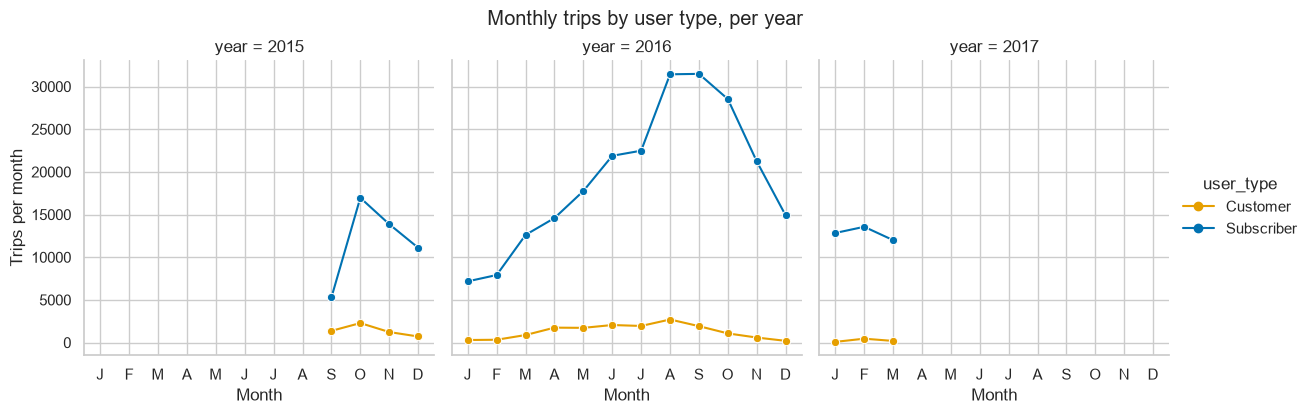

Task 2 - about this visualization

a. Data types:
   Ordinal/temporal: month, year. Nominal: user type. Quantitative: trip count.

b. Marks & channels:
   Marks: line + point. Channels: horizontal position = month, vertical position = trip count,
   colour hue = user type, separate panel (small multiple) = year.

c. Best practices:
   Small multiples with a shared y axis so the years are compared fairly; same user-type colours as
   c and e; months missing from the data are not drawn as zero.

d. Justification:
   Small multiples separate the years while keeping the monthly pattern directly comparable; lines
   emphasise the seasonal shape of each user type.


In [59]:
qj = df.groupby(["year", "month", "user_type"]).size().rename("trips").reset_index()

g = sns.relplot(data=qj, kind="line", x="month", y="trips", hue="user_type", col="year",
                palette=USER_COLORS, marker="o", height=4, aspect=1)
g.set(xticks=range(1, 13), xticklabels=[m[0] for m in MONTHS])
g.set_axis_labels("Month", "Trips per month")
g.figure.suptitle("Monthly trips by user type, per year", y=1.03)
show_chart(10)

print_task2(
    data_types='Ordinal/temporal: month, year. Nominal: user type. Quantitative: trip count.',
    marks_channels=(
        'Marks: line + point. Channels: horizontal position = month, vertical position = trip '
        'count, colour hue = user type, separate panel (small multiple) = year.'
    ),
    best_practices=(
        'Small multiples with a shared y axis so the years are compared fairly; same user-type '
        'colours as c and e; months missing from the data are not drawn as zero.'
    ),
    justification=(
        'Small multiples separate the years while keeping the monthly pattern directly '
        'comparable; lines emphasise the seasonal shape of each user type.'
    ),
)

## k. How has the proportion of trips each gender takes changed over time?

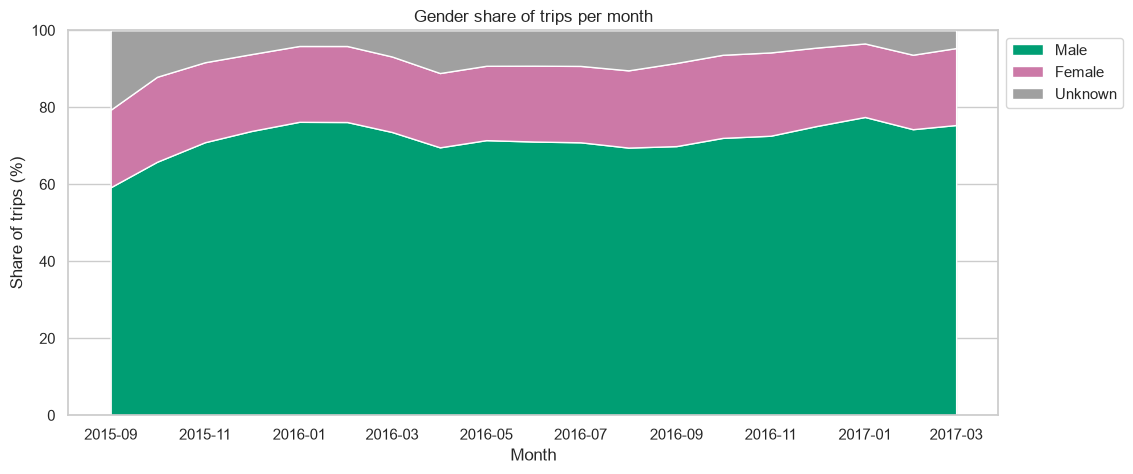

Task 2 - about this visualization

a. Data types:
   Temporal: month. Nominal: gender. Quantitative: share of trips (%).

b. Marks & channels:
   Mark: area. Channels: horizontal position = month, stacked height = % share, colour hue = gender.

c. Best practices:
   100% stacked area so the shares always sum to 100%; same gender colours as b, d and f; y axis
   fixed at 0-100%.

d. Justification:
   A 100% stacked area shows how the shares change continuously over 19 months more smoothly than 19
   separate bars, and still shows the part-to-whole split each month.


In [60]:
qk = pd.crosstab(df["year_month"], df["gender_label"], normalize="index")[["Male", "Female", "Unknown"]] * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(qk.index.to_timestamp(), qk["Male"], qk["Female"], qk["Unknown"],
             labels=qk.columns, colors=[GENDER_COLORS[c] for c in qk.columns])
ax.set_title("Gender share of trips per month")
ax.set_xlabel("Month")
ax.set_ylabel("Share of trips (%)")
ax.set_ylim(0, 100)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
show_chart(11)

print_task2(
    data_types='Temporal: month. Nominal: gender. Quantitative: share of trips (%).',
    marks_channels=(
        'Mark: area. Channels: horizontal position = month, stacked height = % share, colour hue '
        '= gender.'
    ),
    best_practices=(
        '100% stacked area so the shares always sum to 100%; same gender colours as b, d and f; y'
        ' axis fixed at 0-100%.'
    ),
    justification=(
        'A 100% stacked area shows how the shares change continuously over 19 months more '
        'smoothly than 19 separate bars, and still shows the part-to-whole split each month.'
    ),
)

## l. What times of day have the highest trip activity across days of the week?
Counts are divided by the number of dates of each weekday, so the value is average trips per hour.

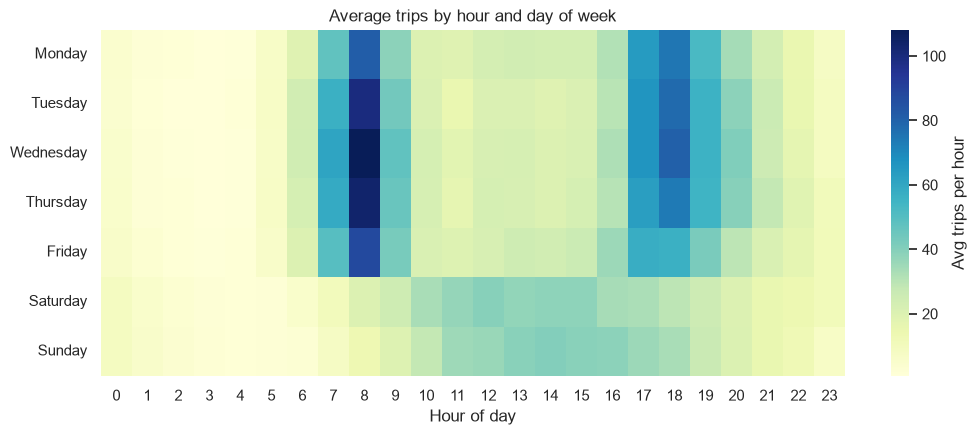

Task 2 - about this visualization

a. Data types:
   Ordinal: day of week, hour of day. Quantitative: average trips per hour.

b. Marks & channels:
   Mark: area (heatmap cell). Channels: horizontal position = hour, vertical position = weekday,
   colour luminance = average trips.

c. Best practices:
   Counts divided by the number of dates of each weekday, so weekdays are compared fairly;
   sequential colormap with a labelled colour bar; weekdays in calendar order.

d. Justification:
   A weekday x hour heatmap shows the weekday commuter peaks and the weekend midday pattern in a
   single view.


In [61]:
counts = df.groupby(["day_of_week", "hour"], observed=True).size().unstack(fill_value=0)
n_dates = df.drop_duplicates("date").groupby("day_of_week", observed=True).size()
ql = counts.div(n_dates, axis=0)

fig, ax = plt.subplots(figsize=(12, 4.5))
sns.heatmap(ql, cmap="YlGnBu", cbar_kws={"label": "Avg trips per hour"}, ax=ax)
ax.set_title("Average trips by hour and day of week")
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
show_chart(12)

print_task2(
    data_types='Ordinal: day of week, hour of day. Quantitative: average trips per hour.',
    marks_channels=(
        'Mark: area (heatmap cell). Channels: horizontal position = hour, vertical position = '
        'weekday, colour luminance = average trips.'
    ),
    best_practices=(
        'Counts divided by the number of dates of each weekday, so weekdays are compared fairly; '
        'sequential colormap with a labelled colour bar; weekdays in calendar order.'
    ),
    justification=(
        'A weekday x hour heatmap shows the weekday commuter peaks and the weekend midday pattern'
        ' in a single view.'
    ),
)

## m. Which station pairs are most frequently used?

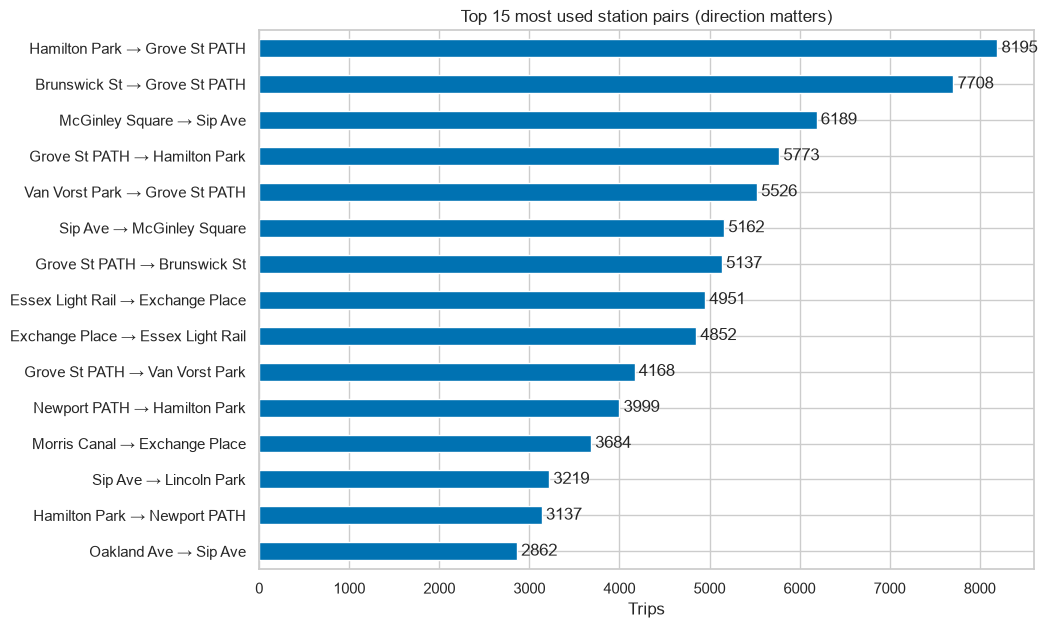

Task 2 - about this visualization

a. Data types:
   Nominal: route (ordered start -> end station pair). Quantitative: trip count.

b. Marks & channels:
   Mark: bar. Channels: vertical position = route, bar length = trip count; text labels = exact
   count.

c. Best practices:
   Bars sorted from most to least used; horizontal bars for long route names; value labels on the
   bars; the title states that direction matters (A -> B and B -> A are separate).

d. Justification:
   A sorted bar chart is the most accurate way to rank a list of categories by size.


In [62]:
qm = (df["start_station_name"] + " → " + df["end_station_name"]).value_counts().head(15)

ax = qm.iloc[::-1].plot.barh(color="#0072B2", figsize=(10, 7))
ax.bar_label(ax.containers[0], padding=3)
ax.set_title("Top 15 most used station pairs (direction matters)")
ax.set_xlabel("Trips")
show_chart(13)

print_task2(
    data_types='Nominal: route (ordered start -> end station pair). Quantitative: trip count.',
    marks_channels=(
        'Mark: bar. Channels: vertical position = route, bar length = trip count; text labels = '
        'exact count.'
    ),
    best_practices=(
        'Bars sorted from most to least used; horizontal bars for long route names; value labels '
        'on the bars; the title states that direction matters (A -> B and B -> A are separate).'
    ),
    justification='A sorted bar chart is the most accurate way to rank a list of categories by size.',
)

## n. Are there certain times of day when trips tend to be longer?
Median line with the middle 50% (IQR) of trips as a band.

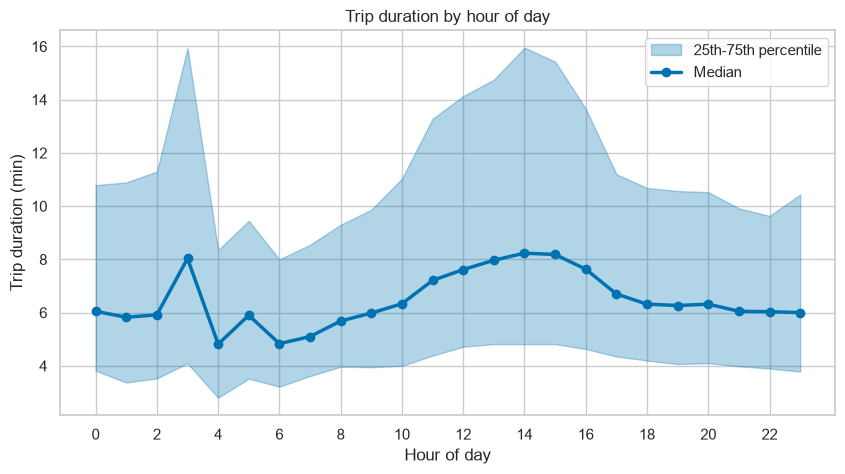

,0.25,0.50,0.75
hour,,,
0,3.8,6.0,10.8
1,3.4,5.8,10.9
2,3.5,5.9,11.3
3,4.1,8.0,15.9
4,2.8,4.8,8.4
5,3.5,5.9,9.4
6,3.2,4.8,8.0
7,3.6,5.1,8.6
8,4.0,5.7,9.3


Task 2 - about this visualization

a. Data types:
   Ordinal: hour of day. Quantitative: trip duration (median and 25th/75th percentiles).

b. Marks & channels:
   Marks: line + points (median) and area (band). Channels: horizontal position = hour, vertical
   position = duration, band width = spread of trip durations.

c. Best practices:
   Percentiles instead of mean so the few very long trips do not distort the scale; the IQR band
   shows the spread, not just the average; zero baseline.

d. Justification:
   A median line with a spread band shows both the typical trip length and its variability per hour
   more compactly than 24 separate box plots.


In [63]:
qn = df.groupby("hour")["duration_min"].quantile([0.25, 0.5, 0.75]).unstack()

fig, ax = plt.subplots()
ax.fill_between(qn.index, qn[0.25], qn[0.75], alpha=0.3, color="#0072B2", label="25th-75th percentile")
ax.plot(qn.index, qn[0.5], marker="o", color="#0072B2", lw=2.5, label="Median")
ax.set_xticks(range(0, 24, 2))
ax.set_title("Trip duration by hour of day")
ax.set_xlabel("Hour of day")
ax.set_ylabel("Trip duration (min)")
ax.legend()
show_chart(14)
display(qn.round(1))

print_task2(
    data_types='Ordinal: hour of day. Quantitative: trip duration (median and 25th/75th percentiles).',
    marks_channels=(
        'Marks: line + points (median) and area (band). Channels: horizontal position = hour, '
        'vertical position = duration, band width = spread of trip durations.'
    ),
    best_practices=(
        'Percentiles instead of mean so the few very long trips do not distort the scale; the IQR'
        ' band shows the spread, not just the average; zero baseline.'
    ),
    justification=(
        'A median line with a spread band shows both the typical trip length and its variability '
        'per hour more compactly than 24 separate box plots.'
    ),
)

## o. Do certain stations have higher traffic on weekends than on weekdays?
Average trips per day (weekday vs weekend) per start station, because a week has 5 weekdays but only 2 weekend days.
Stations with fewer than 5 trips/day are left out. Top 15 by weekend/weekday ratio.

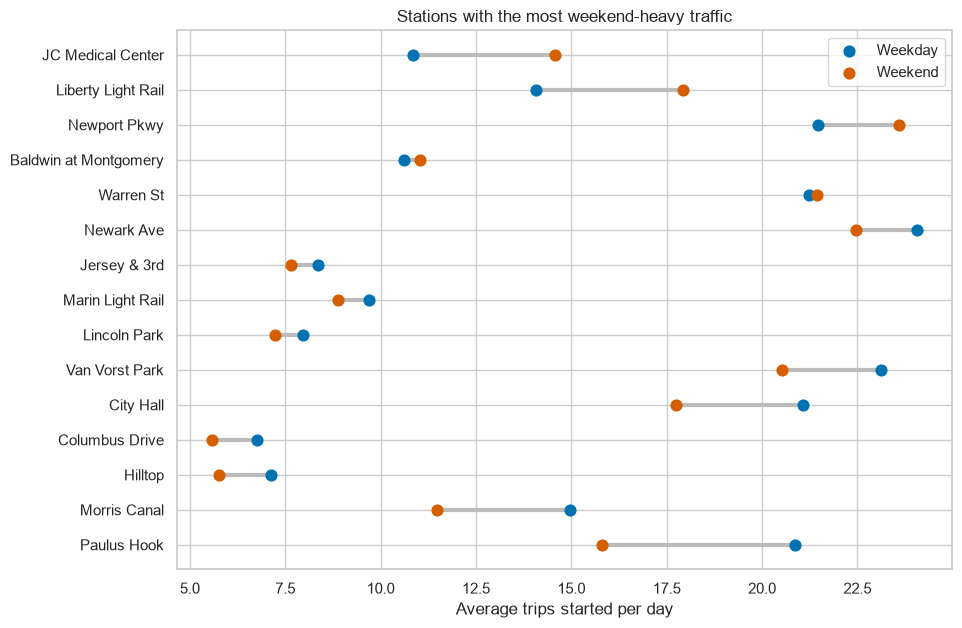

,weekday,weekend,ratio
start_station_name,,,
JC Medical Center,10.84,14.58,1.35
Liberty Light Rail,14.07,17.94,1.28
Newport Pkwy,21.46,23.60,1.10
Baldwin at Montgomery,10.62,11.03,1.04
Warren St,21.24,21.44,1.01
Newark Ave,24.06,22.47,0.93
Jersey & 3rd,8.35,7.65,0.92
Marin Light Rail,9.70,8.88,0.92
Lincoln Park,7.97,7.22,0.91


Task 2 - about this visualization

a. Data types:
   Nominal: start station. Quantitative: average trips per day on weekdays and weekends,
   weekend/weekday ratio.

b. Marks & channels:
   Marks: point + line (dumbbell). Channels: vertical position = station, horizontal position =
   average daily trips, colour hue = weekday vs weekend, connector length = the difference.

c. Best practices:
   Normalised per day (a week has 5 weekdays but only 2 weekend days); low-traffic stations (< 5
   trips/day) removed so ratios are not based on tiny counts; sorted by the weekend/weekday ratio;
   ratio table printed.

d. Justification:
   A dumbbell chart compares two values per category and shows both the size and the direction of
   the gap, with less clutter than grouped bars.


In [64]:
n_days = df.drop_duplicates("date")["is_weekend"].value_counts()
station_counts = pd.crosstab(df["start_station_name"], df["is_weekend"])
qo = pd.DataFrame({
    "weekday": station_counts[False] / n_days[False],
    "weekend": station_counts[True] / n_days[True],
})
qo["ratio"] = qo["weekend"] / qo["weekday"]
qo = qo[station_counts.sum(axis=1) / n_days.sum() >= 5]
qo = qo.sort_values("ratio", ascending=False).head(15)

data = qo.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.hlines(data.index, data["weekday"], data["weekend"], color="#BBBBBB", lw=3)
ax.scatter(data["weekday"], data.index, color="#0072B2", s=60, label="Weekday", zorder=2)
ax.scatter(data["weekend"], data.index, color="#D55E00", s=60, label="Weekend", zorder=2)
ax.set_title("Stations with the most weekend-heavy traffic")
ax.set_xlabel("Average trips started per day")
ax.legend()
show_chart(15)
display(qo.round(2))

print_task2(
    data_types=(
        'Nominal: start station. Quantitative: average trips per day on weekdays and weekends, '
        'weekend/weekday ratio.'
    ),
    marks_channels=(
        'Marks: point + line (dumbbell). Channels: vertical position = station, horizontal '
        'position = average daily trips, colour hue = weekday vs weekend, connector length = the '
        'difference.'
    ),
    best_practices=(
        'Normalised per day (a week has 5 weekdays but only 2 weekend days); low-traffic stations'
        ' (< 5 trips/day) removed so ratios are not based on tiny counts; sorted by the '
        'weekend/weekday ratio; ratio table printed.'
    ),
    justification=(
        'A dumbbell chart compares two values per category and shows both the size and the '
        'direction of the gap, with less clutter than grouped bars.'
    ),
)